# Exercise 5: Seismic Deconvolution with a Recurrent Neural Network

- **Course:** PPGEEC2327, Special Topics in Intelligent Information Processing (AI applied to Geophysics), UFRN
- **Reference:** Schuster, G. (2024), *Machine Learning Methods in Geoscience*, SEG, Chapter 12
- **Task:** carry out activities (1), (2), and (3) from the lab's Section 6, Questions, and submit the analysis.
- **Materials:** the official lab page returns a TLS certificate error over HTTPS but is reachable over plain
  HTTP. `RNN_lab.zip`, including `RNN_deconv.m`, `ricker.m`, and `RNN_binary_lstm.m`, was downloaded from
  there and is mirrored at `materials/RNN_lab`.

The lab trains a recurrent neural network (RNN) to recover a sparse reflectivity series from a seismogram, the
inverse of convolution with a seismic wavelet. `RNN_deconv.m` builds the training and test data and trains a
MATLAB `layrecnet` (a single-hidden-layer Elman-style RNN with one-step feedback) using `trainlm`
(Levenberg-Marquardt). PyTorch has no Levenberg-Marquardt optimizer, so this notebook uses `torch.optim.LBFGS`,
the closest available quasi-Newton method, as a documented substitution.

## 1. Data: seismogram and reflectivity

`ricker.m` generates a 1 Hz Ricker wavelet. The reflectivity series is 2000 samples long with a random-amplitude
spike every 20 samples (100 spikes total); the seismogram is the convolution of the reflectivity with the
wavelet. The test series uses 9 fixed spikes at known positions and amplitudes, exactly as in `RNN_deconv.m`.

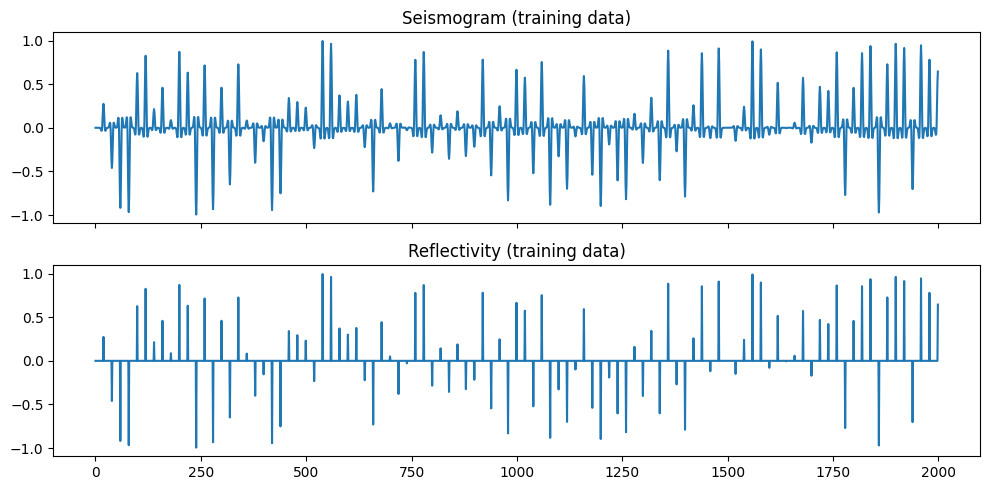

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)


def ricker(npnt, fr, dt):
    '''Port of ricker.m: a Ricker wavelet of length npnt, center frequency fr, sample interval dt.'''
    npt = npnt * dt
    t = np.linspace(-npt / 2, npt / 2, round(npt / dt) + 1)
    rick1 = (1 - t ** 2 * fr ** 2 * np.pi ** 2) * np.exp(-t ** 2 * np.pi ** 2 * fr ** 2)
    start = round(npnt / 2) - round(1 / fr / dt)
    return rick1[start:npnt]


rick = ricker(1000, 1, 0.1)

y = np.zeros(2000)  # reflectivity (training)
for ii in range(1, 101):
    y[20 * ii - 1] = 2 * rng.random() - 1
x = np.convolve(rick, y)[10:2010]  # seismogram (training)

test_y = np.zeros(200)  # reflectivity (test)
spikes = {20: 0.5, 40: 0.7, 60: -0.2, 80: -0.3, 100: 0.7, 120: 0.9, 140: -0.8, 160: -0.3, 180: 0.5}
for pos, amp in spikes.items():
    test_y[pos - 1] = amp
test_x = np.convolve(rick, test_y)[10:210]  # seismogram (test)

x_t = torch.tensor(x, dtype=torch.float32).view(1, -1, 1)
y_t = torch.tensor(y, dtype=torch.float32).view(1, -1, 1)
test_x_t = torch.tensor(test_x, dtype=torch.float32).view(1, -1, 1)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(x)
axes[0].set_title("Seismogram (training data)")
axes[1].plot(y)
axes[1].set_title("Reflectivity (training data)")
plt.tight_layout()
plt.show()

## 2. RNN architecture

`layrecnet(1, [10], 'trainlm')` is a single hidden layer of 10 units with a one-sample feedback delay, `tansig`
hidden activation, and `purelin` output. This maps to `nn.RNN(input_size=1, hidden_size=10,
nonlinearity='tanh')` followed by `nn.Linear(10, 1)` with no output activation.

train MSE: 2.249e-05
test MSE:  1.290e-05


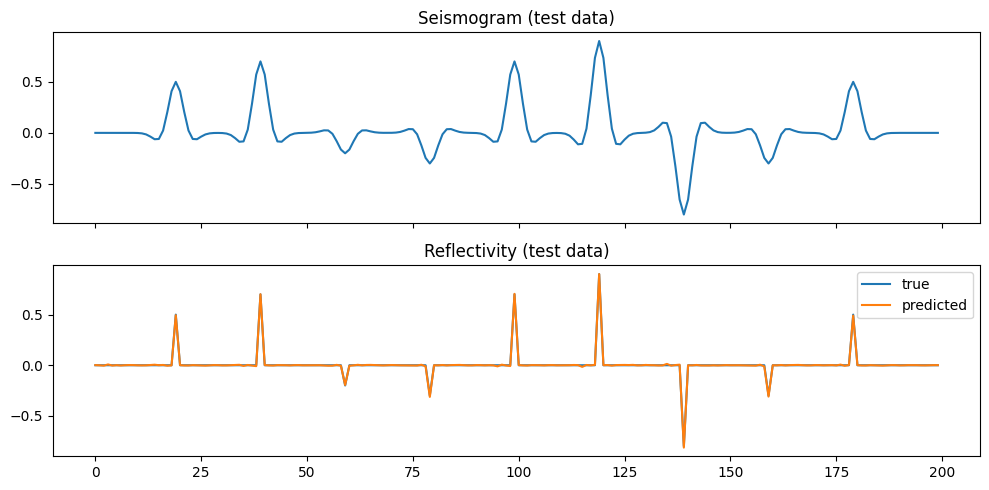

In [2]:
class VanillaRNN(nn.Module):
    def __init__(self, hidden_size=10):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=hidden_size, nonlinearity="tanh", batch_first=True)
        self.out = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h, _ = self.rnn(x)
        return self.out(h)


def train_rnn(model, x_in, y_target, steps=60):
    opt = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=20, history_size=10,
                             line_search_fn="strong_wolfe")
    loss_fn = nn.MSELoss()
    last = [None]

    def closure():
        opt.zero_grad()
        loss = loss_fn(model(x_in), y_target)
        loss.backward()
        last[0] = loss.item()
        return loss

    for _ in range(steps):
        opt.step(closure)
    return last[0]


torch.manual_seed(0)
model = VanillaRNN(hidden_size=10)
train_loss = train_rnn(model, x_t, y_t)

with torch.no_grad():
    pred_train = model(x_t).squeeze().numpy()
    pred_test = model(test_x_t).squeeze().numpy()
test_mse = np.mean((pred_test - test_y) ** 2)
print(f"train MSE: {train_loss:.3e}")
print(f"test MSE:  {test_mse:.3e}")

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(test_x)
axes[0].set_title("Seismogram (test data)")
axes[1].plot(test_y, label="true")
axes[1].plot(pred_test, label="predicted")
axes[1].set_title("Reflectivity (test data)")
axes[1].legend()
plt.tight_layout()
plt.show()

## Activity 1: seismogram as output instead of input

Section 6 asks: *"Use the reflectivity as the input data and the seismogram as the output, which means using
RNN to mimic convolution. How does the result looks like? Why is that?"* (`RNN_deconv.m` even has this swap
commented out: `%n=x;m=y;y=n;x=m;`.) The same architecture and training procedure is retrained with the input
and target swapped.

train MSE (reflectivity -> seismogram): 1.639e-02
test MSE  (reflectivity -> seismogram): 1.365e-02
for comparison, deconvolution test MSE: 1.290e-05


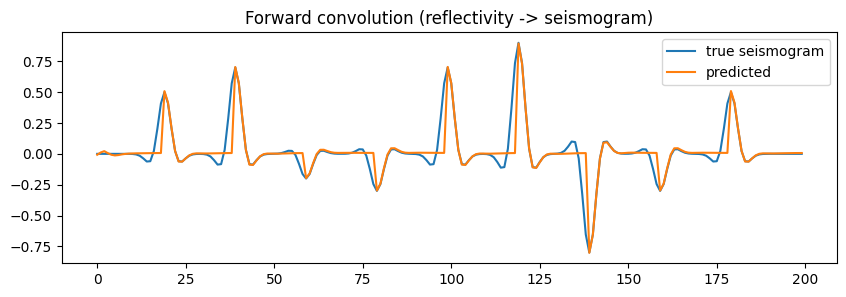

In [3]:
torch.manual_seed(0)
model_swap = VanillaRNN(hidden_size=10)
train_loss_swap = train_rnn(model_swap, y_t, x_t)

test_y_t = torch.tensor(test_y, dtype=torch.float32).view(1, -1, 1)
with torch.no_grad():
    pred_test_swap = model_swap(test_y_t).squeeze().numpy()
test_mse_swap = np.mean((pred_test_swap - test_x) ** 2)
print(f"train MSE (reflectivity -> seismogram): {train_loss_swap:.3e}")
print(f"test MSE  (reflectivity -> seismogram): {test_mse_swap:.3e}")
print(f"for comparison, deconvolution test MSE: {test_mse:.3e}")

plt.figure(figsize=(10, 3))
plt.plot(test_x, label="true seismogram")
plt.plot(pred_test_swap, label="predicted")
plt.title("Forward convolution (reflectivity -> seismogram)")
plt.legend()
plt.show()

The swapped direction trains to a much worse, stable error: increasing the number of LBFGS steps from 60 to
300 does not improve it further. The deconvolution target (reflectivity) is a sparse series of near-zero
samples with a few spikes, which an MSE loss fits almost for free by predicting close to zero everywhere. The
forward-convolution target (the seismogram) is smooth and non-zero at every sample, a much harder regression
target for a small causal RNN with only one step of feedback. The RNN can mimic deconvolution far more easily
than it can mimic convolution, because the two targets are not equally difficult to fit, not because the
network architecture favors one direction over the other.

## Activity 2: hidden layer size

Section 6 also asks to modify the RNN's structure and parameters and observe the effect. Here the hidden layer
size is swept over {2, 5, 10, 20, 50} (`layrecnet(1, [hidden], 'trainlm')` with varying `hidden`), training each
network from the same procedure as above and measuring the resulting test-set error.

hidden=  2  train_mse=1.074e-02  test_mse=8.552e-03


hidden=  5  train_mse=8.678e-05  test_mse=6.943e-05


hidden= 10  train_mse=2.249e-05  test_mse=1.290e-05


hidden= 20  train_mse=5.044e-06  test_mse=3.781e-06


hidden= 50  train_mse=3.581e-06  test_mse=1.991e-06


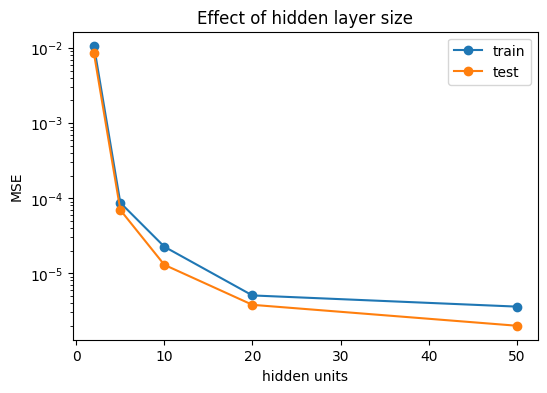

In [4]:
results = []
for hidden in [2, 5, 10, 20, 50]:
    torch.manual_seed(0)
    m = VanillaRNN(hidden_size=hidden)
    tl = train_rnn(m, x_t, y_t)
    with torch.no_grad():
        p = m(test_x_t).squeeze().numpy()
    mse = np.mean((p - test_y) ** 2)
    results.append((hidden, tl, mse))
    print(f"hidden={hidden:3d}  train_mse={tl:.3e}  test_mse={mse:.3e}")

hiddens, train_mses, test_mses = zip(*results)
plt.figure(figsize=(6, 4))
plt.semilogy(hiddens, train_mses, "o-", label="train")
plt.semilogy(hiddens, test_mses, "o-", label="test")
plt.xlabel("hidden units")
plt.ylabel("MSE")
plt.legend()
plt.title("Effect of hidden layer size")
plt.show()

Error drops sharply from 2 to 10 hidden units (test MSE falls from about 8.6e-3 to 1.3e-5), then keeps
improving only marginally from 10 to 50 units. Two hidden units cannot represent the wavelet's shape well
enough to invert it; 10 units, the lab's own default, already captures the dynamics needed for this task, and
larger networks mostly add capacity the problem does not need.

## Activity 3: LSTM binary addition

Section 6's last point: *"This lab uses the conventional RNN without gate. If you are interested in LSTM, a
binary calculator trained by LSTM is in `./RNN_binary_lstm.m`."* That file implements an LSTM from scratch and
trains it to add two 8-bit binary numbers. Its backward pass has some derivative terms deliberately commented
out (e.g. `H_t_diff = output_diff * (out_para');% .* sigmoid_output_to_derivative(H_t);`), an acknowledged
simplification in the official code. Rather than port that simplified gradient by hand, this notebook uses
PyTorch's `nn.LSTM` with autograd, which computes the exact gradients, as a documented, correctness-motivated
deviation from the official script.

In [5]:
torch.manual_seed(0)
rng2 = np.random.default_rng(0)

binary_dim = 8
largest_number = 2 ** binary_dim - 1


def to_bits(n, width=binary_dim):
    return np.array([int(b) for b in format(n, f"0{width}b")], dtype=np.float32)


def make_example():
    a_int = rng2.integers(0, largest_number // 2 + 1)
    b_int = rng2.integers(0, largest_number // 2 + 1)
    c_int = a_int + b_int
    a_bits = to_bits(a_int)[::-1].copy()  # least-significant bit first
    b_bits = to_bits(b_int)[::-1].copy()
    c_bits = to_bits(c_int)[::-1].copy()
    X = np.stack([a_bits, b_bits], axis=1)  # (time, 2)
    return X, c_bits, a_int, b_int, c_int


class BinaryAdderLSTM(nn.Module):
    def __init__(self, hidden_dim=32):
        super().__init__()
        self.lstm = nn.LSTM(input_size=2, hidden_size=hidden_dim, batch_first=True)
        self.out = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        h, _ = self.lstm(x)
        return torch.sigmoid(self.out(h)).squeeze(-1)


lstm_model = BinaryAdderLSTM(hidden_dim=32)
opt = torch.optim.Adam(lstm_model.parameters(), lr=0.05)
loss_fn = nn.BCELoss()

losses = []
for it in range(3000):
    X, c_bits, a_int, b_int, c_int = make_example()
    X_t = torch.tensor(X, dtype=torch.float32).unsqueeze(0)
    target = torch.tensor(c_bits, dtype=torch.float32).unsqueeze(0)
    opt.zero_grad()
    pred = lstm_model(X_t)
    loss = loss_fn(pred, target)
    loss.backward()
    opt.step()
    losses.append(loss.item())
    if (it + 1) % 500 == 0:
        with torch.no_grad():
            pred_bits = (pred.squeeze(0).numpy() > 0.5).astype(int)
        pred_int = int("".join(str(b) for b in pred_bits[::-1]), 2)
        print(f"iter {it + 1}: loss={np.mean(losses[-500:]):.4f}  {a_int}+{b_int}={pred_int} (true {c_int})")

iter 500: loss=0.3499  26+107=133 (true 133)


iter 1000: loss=0.0131  33+48=81 (true 81)


iter 1500: loss=0.0027  15+49=64 (true 64)


iter 2000: loss=0.0008  30+41=71 (true 71)


iter 2500: loss=0.0004  34+11=45 (true 45)


iter 3000: loss=0.0002  30+38=68 (true 68)


In [6]:
correct = 0
n_eval = 200
for _ in range(n_eval):
    X, c_bits, a_int, b_int, c_int = make_example()
    X_t = torch.tensor(X, dtype=torch.float32).unsqueeze(0)
    with torch.no_grad():
        pred = lstm_model(X_t).squeeze(0).numpy()
    pred_bits = (pred > 0.5).astype(int)
    pred_int = int("".join(str(b) for b in pred_bits[::-1]), 2)
    correct += (pred_int == c_int)
print(f"exact-match accuracy over {n_eval} random additions: {correct / n_eval:.2%}")

exact-match accuracy over 200 random additions: 100.00%


## Discussion

The vanilla RNN solves the deconvolution task the lab sets up almost exactly (test MSE around 1.3e-5 with 10
hidden units), because the target reflectivity is sparse and mostly zero. The same network trained in the
opposite direction, to reproduce convolution, plateaus at a much higher, stable error: the task is harder, not
because gated units are required, but because the forward-convolution target is dense everywhere. Hidden-layer
size matters up to a point (2 units is clearly too small; 10 is already enough) and then gives diminishing
returns. The LSTM binary-adder task, unrelated to deconvolution but included in the same lab to contrast gated
and non-gated recurrent networks, reaches 100% exact-match accuracy on random 8-bit additions once trained with
correct gradients, confirming that the official script's simplified backward pass was a shortcut in the
reference implementation rather than a limitation of the LSTM architecture itself.